# Steam EDA

Goal: the facts the **Exploratory Analysis** section needs, and the ones that justify
our modeling and evaluation choices (ranking with leave-one-out, popularity baseline,
`1 + log1p(playtime)` target, uniform negatives).

Each section: the question, why it matters for the write-up, and hints. Keep cells
short; anything reusable moves into `src/`. Save figures you want in the slides to
`cfg.paths.figures`.

In [5]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from assignment_2.modules.config import get_config
from assignment_2.modules.core import ranking_per_user, top_share
from assignment_2.modules.core.plots import log_hist, save, use_style
from assignment_2.modules.data import load_prepped, read_meta
from assignment_2.modules.data.records import records


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
# Style plots
use_style()

In [7]:
cfg = get_config()
print(f"dataset={cfg.dataset}  sample={cfg.sample.tag}  seed={cfg.seed}")

meta = read_meta(cfg)
t = load_prepped(cfg)
# own train + valid + test together are every owned (user, game): the full table the
# EDA was originally run on, before the task splits.
owned = pd.concat([t[f"own_{s}"] for s in ("train", "valid", "test")], ignore_index=True)
items, bundles, reviews = t["items"], t["bundles"], t["reviews"]
sorted(t)

dataset=steam  sample=users_0.1  seed=258


['bundles',
 'items',
 'own_test',
 'own_train',
 'own_valid',
 'play_test',
 'play_test_candidates',
 'play_train',
 'play_valid',
 'play_valid_candidates',
 'reviews']

## 1. Dataset summary
The first slide of the EDA section. Built from `meta.json`, so it matches exactly
what `prep` produced.

In [8]:
s = meta["stats"]


def split_rows(task: dict) -> str:
    return "{:,} / {:,} / {:,}".format(*(task[k]["rows"] for k in ("train", "valid", "test")))


rows = {
    "users": s["own"]["all"]["users"],
    "games (owned by anyone)": s["own"]["all"]["items"],
    "ownership rows": s["own"]["all"]["rows"],
    "sparsity": round(s["own"]["all"]["sparsity"], 4),
    "play: train / valid / test rows": split_rows(s["play"]),
    "play: unplayed rows added to train": s["play"]["unplayed_added_to_train"],
    "play: cold held-out rows dropped": s["play"]["cold_dropped"],
    "own: train / valid / test rows": split_rows(s["own"]),
    "own: cold held-out rows dropped": s["own"]["cold_dropped"],
    "games with metadata": s["items"]["rows"],
    "reviews": s["reviews"]["rows"],
    "reviews with no year": f"{s['reviews']['undated_share']:.1%}",
    "bundles": s["bundles"]["bundles"],
}
pd.Series(rows, name=cfg.sample.tag).to_frame()

,users_0.1
users,7058
games (owned by anyone),8372
ownership rows,490861
sparsity,0.9917
play: train / valid / test rows,"477,901 / 5,946 / 5,949"
play: unplayed rows added to train,301249
play: cold held-out rows dropped,45
own: train / valid / test rows,"454,741 / 18,034 / 18,041"
own: cold held-out rows dropped,45
games with metadata,32132


## 2. How concentrated is ownership? (the long tail)
**Why:** if a few games account for most ownership, popularity is a strong baseline,
and that's the bar every model has to clear. It also explains why sampled negatives
are mostly obscure games.

**Do:**
- games per user: `owned.groupby("user_id").size()`; describe() + histogram (log x).
- owners per game: `owned.item_id.value_counts()`; plot rank vs count on log-log axes.
- share of all ownership rows covered by the top 1% / 10% of games
  (sort counts descending, `cumsum() / total`).

**Write-up line:** "The top X% of games account for Y% of ownership."

In [9]:
games_per_user = owned.groupby('user_id').size()
games_per_user.describe()

count    7058.000000
mean       69.540380
std       110.126123
min         1.000000
25%        14.000000
50%        40.000000
75%        86.000000
max      3730.000000
dtype: float64

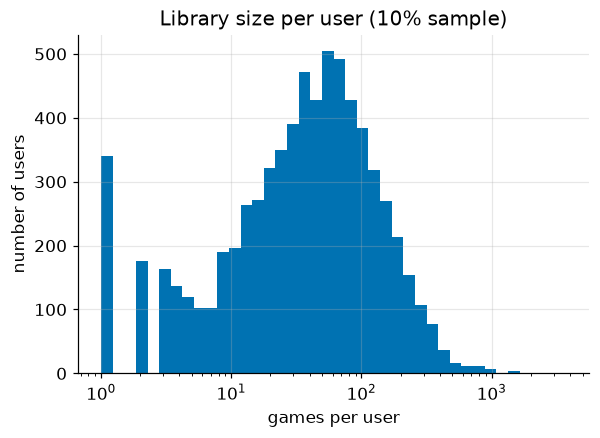

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))   # a figure and one set of axes
log_hist(ax, games_per_user, "games per user", "number of users", "Library size per user (10% sample)")
path = save(fig, "games_per_user")

plt.show()

In [11]:
owners_per_game = owned['item_id'].value_counts()
owners_per_game.describe()


count    8328.000000
mean       58.935639
std       201.741681
min         1.000000
25%         2.000000
50%         8.000000
75%        32.000000
max      4905.000000
Name: count, dtype: float64

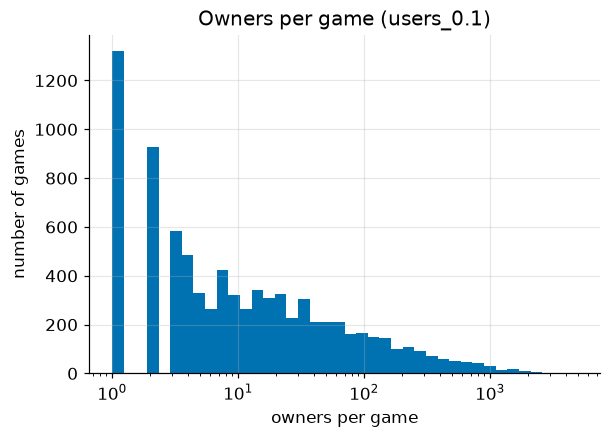

In [12]:
fig, ax = plt.subplots()
log_hist(ax, owners_per_game, "owners per game", "number of games", f"Owners per game ({cfg.sample.tag})")
save(fig, "owners_per_game")
plt.show()

In [13]:
assert top_share(pd.Series([50, 30, 10, 5, 5]), 0.4) == 0.8   # top 2 of 5 games

for frac in (0.01, 0.10, 0.50):
    print(f"top {frac:.0%} of games: {top_share(owners_per_game, frac):.1%} of ownership")

top 1% of games: 26.7% of ownership
top 10% of games: 74.0% of ownership
top 50% of games: 97.6% of ownership


## 3. Playtime: is "owned" the same as "played"?
**Why:** justifies the training target. If many owned games have 0 minutes, ownership
alone is a weak signal; that's why owned rows get `1 + log1p(playtime)`, so
owned-but-unplayed (target 1) stays above not-owned (0).

**Do:**
- share of ownership rows with `playtime_forever == 0`.
- histogram of `np.log1p(playtime_forever)` for played rows (raw playtime is far too
  skewed to plot directly; note the units are minutes).
- per user: share of their library never played. Is it a few users or everyone?

In [14]:
played = owned.playtime_forever > 0
stats = pd.Series({
    "ownership rows": f"{len(owned):,}",
    "never played (lifetime)": f"{(~played).mean():.1%}",
    "not played in last 2 weeks": f"{(owned.playtime_2weeks == 0).mean():.1%}",
}, name="value")
stats.to_frame()

,value
ownership rows,"490,816"
never played (lifetime),35.9%
not played in last 2 weeks,97.3%


36% of owned games have never been played, so ownership alone is a noisy signal of preference.

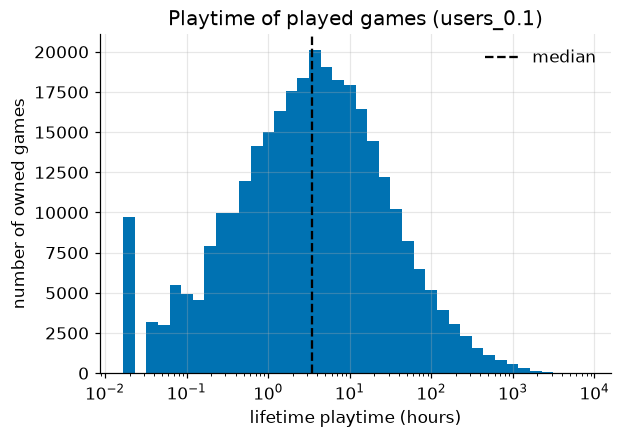

Median playtime of played games: 3.5 hours


In [15]:
played_hours = owned.loc[played, "playtime_forever"] / 60

fig, ax = plt.subplots()
log_hist(ax, played_hours, "lifetime playtime (hours)", "number of owned games",
         f"Playtime of played games ({cfg.sample.tag})")
ax.axvline(played_hours.median(), linestyle="--", color="black", label="median")
ax.legend()
save(fig, "playtime_played")
plt.show()

print(f"Median playtime of played games: {played_hours.median():.1f} hours")

In [16]:
for cutoff in (1, 5, 30, 120):                       # minutes
    share = (owned.playtime_forever < cutoff).mean()   # share of ALL owned rows with playtime_forever < cutoff
    print(f"< {cutoff:>3} min: {share:.1%} of owned games")

<   1 min: 35.9% of owned games
<   5 min: 39.7% of owned games
<  30 min: 48.6% of owned games
< 120 min: 61.6% of owned games


In [17]:
for frac in (0.01, 0.10, 0.50):
    share = top_share(played_hours, frac)
    print(f"top {frac:.0%} of played (user, game) pairs: {share:.1%} of all hours played")

top 1% of played (user, game) pairs: 33.5% of all hours played
top 10% of played (user, game) pairs: 76.6% of all hours played
top 50% of played (user, game) pairs: 98.0% of all hours played


Playtime is extremely skewed: 1% of played (user, game) pairs account for 33% of all hours. We therefore model log(1 + minutes) rather than raw playtime, which makes the distribution roughly symmetric (see histogram).

## 4. Do popular games get played more?
**Why:** if popularity and playtime are strongly related, the playtime target mostly
re-encodes popularity; if not, it adds signal beyond it (experiment 2 vs 1 in the plan).

**Do:** per game, number of owners vs median `log1p(playtime)` among owners (scatter,
log x). Report a rank correlation (`scipy.stats.spearmanr`).

In [18]:
owned = owned.assign(log_playtime=np.log1p(owned.playtime_forever))

per_game = owned.groupby("item_id").agg(
    owners=("user_id", "size"),
    median_log_playtime=("log_playtime", "median"),
    median_hours=("playtime_forever", lambda s: s.median() / 60),
)
per_game.describe()

,owners,median_log_playtime,median_hours
count,8328.000000,8328.000000,8328.000000
mean,58.935639,1.953310,1.668665
std,201.741681,2.224536,9.870665
min,1.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000
50%,8.000000,0.693147,0.025000
75%,32.000000,3.871038,1.033333
max,4905.000000,10.318606,504.833333


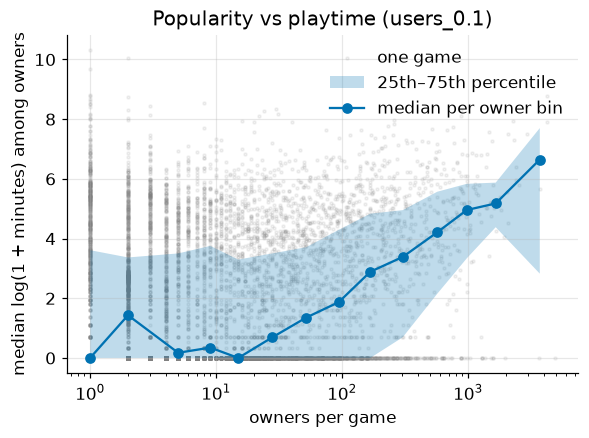

Spearman ρ = 0.19 across 5,013 games with ≥ 5 owners


,owners,mid,lo,hi,n_games
bin,,,,,
"(0.999, 1.835]",1.0,0.00,0.00,3.61,1322
"(1.835, 3.367]",2.0,1.43,0.00,3.37,1510
"(3.367, 6.178]",5.0,0.17,0.00,3.50,1074
"(6.178, 11.336]",9.0,0.35,0.00,3.75,881
"(11.336, 20.801]",15.0,0.00,0.00,3.30,860
"(20.801, 38.168]",28.0,0.69,0.00,3.50,810
"(38.168, 70.036]",52.0,1.35,0.00,3.71,595
"(70.036, 128.51]",94.0,1.87,0.00,4.29,463
"(128.51, 235.805]",167.5,2.89,0.00,4.83,344


In [19]:
MIN_OWNERS = 5  # games with fewer owners have a "median" of 1-4 people; too noisy to read

edges = np.geomspace(1, per_game.owners.max(), 15)
binned = (
    per_game.assign(bin=pd.cut(per_game.owners, bins=edges, include_lowest=True))
    .groupby("bin", observed=True)
    .agg(
        owners=("owners", "median"),
        mid=("median_log_playtime", "median"),
        lo=("median_log_playtime", lambda s: s.quantile(0.25)),
        hi=("median_log_playtime", lambda s: s.quantile(0.75)),
        n_games=("owners", "size"),
    )
)

fig, ax = plt.subplots()
ax.scatter(per_game.owners, per_game.median_log_playtime, s=4, alpha=0.1, color="gray", label="one game")
ax.fill_between(binned.owners, binned.lo, binned.hi, alpha=0.25, label="25th–75th percentile")
ax.plot(binned.owners, binned.mid, marker="o", label="median per owner bin")
ax.set(xscale="log", xlabel="owners per game", ylabel="median log(1 + minutes) among owners",
       title=f"Popularity vs playtime ({cfg.sample.tag})")
ax.legend()
save(fig, "popularity_vs_playtime")
plt.show()

frequent = per_game[per_game.owners >= MIN_OWNERS]
rho, p = spearmanr(frequent.owners, frequent.median_log_playtime)
print(f"Spearman ρ = {rho:.2f} across {len(frequent):,} games with ≥ {MIN_OWNERS} owners")
binned.round(2)

how many owners open the game at all, and how much those who open it play

In [20]:
per_game = owned.groupby("item_id").agg(
    owners=("user_id", "size"),
    median_log_playtime=("log_playtime", "median"),
    median_hours=("playtime_forever", lambda s: s.median() / 60),
    play_rate=("playtime_forever", lambda s: (s > 0).mean()),
    played_median_log=("log_playtime", lambda s: s[s > 0].median()),
)
per_game.describe()

,owners,median_log_playtime,median_hours,play_rate,played_median_log
count,8328.000000,8328.000000,8328.000000,8328.000000,6675.000000
mean,58.935639,1.953310,1.668665,0.482683,4.284090
std,201.741681,2.224536,9.870665,0.348139,1.471894
min,1.000000,0.000000,0.000000,0.000000,0.693147
25%,2.000000,0.000000,0.000000,0.166667,3.320916
50%,8.000000,0.693147,0.025000,0.500000,4.442651
75%,32.000000,3.871038,1.033333,0.771852,5.322766
max,4905.000000,10.318606,504.833333,1.000000,11.209764


In [21]:
f = per_game[per_game.owners >= MIN_OWNERS]
for col in ("play_rate", "played_median_log"):
    rho, _ = spearmanr(f.owners, f[col], nan_policy="omit")
    print(f"owners vs {col}: ρ = {rho:.2f}")

owners vs play_rate: ρ = 0.20
owners vs played_median_log: ρ = 0.13


Engagement is largely independent of popularity: across games with ≥ 5 owners, the share of owners who ever play a game (ρ = 0.20) and how long players play it (ρ = 0.13) are only weakly correlated with its number of owners. 20% of games were never opened by any owner, and for the typical game only half its owners played it.

## 5. Metadata and bundle coverage
**Why:** genre/tag and bundle features only help games that have them. Coverage
decides whether they're worth building.

**Do:**
- share of owned games (and of ownership *rows*) whose `item_id` is in `items`.
  Rows matter more: popular games dominate rows.
- most common genres among owned games: `items.explode("genres")`, joined to ownership.
- share of owned games that appear in any bundle.

In [22]:
has_meta = owned.item_id.isin(items.item_id)   # one True/False per ownership row

by_game = has_meta.groupby(owned.item_id).first()   # one flag per distinct game

print(f"metadata coverage: {by_game.mean():.1%} of owned games, "
      f"{has_meta.mean():.1%} of ownership rows")

# Which popular games are missing metadata? (decides whether it matters)
missing = owners_per_game[~owners_per_game.index.isin(items.item_id)]
missing.head(10)

metadata coverage: 84.5% of owned games, 83.1% of ownership rows


item_id
205790    4905
223530    3663
72850     2268
232210    1578
219540    1526
33910     1466
243870    1419
238960    1275
222900    1258
219740    1219
Name: count, dtype: int64

In [23]:
print("original Skyrim (72850) in metadata:", "72850" in set(items.item_id))
items.item_id.head(), items.item_id.dtype, owned.item_id.dtype
items[items.name.str.contains("Skyrim", case=False, na=False)][["item_id", "name"]]

original Skyrim (72850) in metadata: False


,item_id,name
4162,365720,Skyrim Script Extender (SKSE)
7765,489830,The Elder Scrolls V: Skyrim Special Edition
11645,598120,The Elder Scrolls V: Skyrim Special Edition - ...


In [24]:
raw = cfg.paths.data_dir / "steam" / "steam_games.json.gz"
no_id = [g for g in records(raw) if g.get("id") is None]
print(f"{len(no_id):,} metadata rows have no id")

top = ["205790", "223530", "72850", "232210", "219540"]
hits = [g for g in records(raw) if any(f"/app/{t}/" in str(g.get("url", "")) for t in top)]
[(g.get("id"), g.get("app_name") or g.get("title"), g.get("url")) for g in hits]

2 metadata rows have no id


[]

In [25]:
genres = items[["item_id", "genres"]].explode("genres").dropna(subset=["genres"])
owned_genres = owned[["item_id"]].merge(genres, on="item_id", how="inner")   # which join type?
top_genres = owned_genres["genres"].value_counts(normalize=True)           # counts or shares?
top_genres.head(10)

genres
Action                   0.283691
Indie                    0.173748
Adventure                0.115738
RPG                      0.091739
Strategy                 0.079663
Free to Play             0.077147
Simulation               0.054034
Casual                   0.048458
Massively Multiplayer    0.038384
Early Access             0.012339
Name: proportion, dtype: float64

In [26]:
in_bundle = owned.item_id.isin(bundles.item_id)
print(f"in any bundle: {in_bundle.groupby(owned.item_id).first().mean():.1%} of owned games, "
      f"{in_bundle.mean():.1%} of ownership rows")

in any bundle: 13.6% of owned games, 20.7% of ownership rows


In [27]:
played = owned.playtime_forever > 0
played.groupby(in_bundle).mean()

item_id
False    0.62605
True     0.69756
Name: playtime_forever, dtype: float64

Bundled games are owned more widely and played slightly more often (70% vs 63% of ownership rows have any playtime), likely because bundles favor popular titles.

## 6. Reviews
**Why:** context for the dataset section, and the only data with timestamps.

**Do:**
- share of reviews with `recommend == True`.
- reviews per year (`posted.dt.year.value_counts()`), plus the undated share.
- how many reviewers also appear in the ownership data?

In [28]:
# recommend rate, reviews per year, overlap with owners
reviews.recommend.mean()

np.float64(0.891165602955996)

In [29]:
years = reviews.posted.dt.year.value_counts(dropna=False).sort_index()
years.index = [str(int(y)) if pd.notna(y) else "no year" for y in years.index]
years



2010         15
2011         64
2012        151
2013        677
2014       2230
2015       1834
no year     983
Name: count, dtype: int64

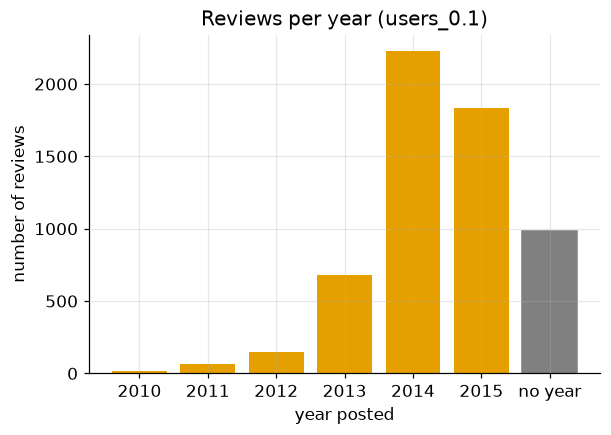

In [30]:
fig, ax = plt.subplots()
ax.bar(years.index, years.values)
ax.set(xlabel="year posted", ylabel="number of reviews",
       title=f"Reviews per year ({cfg.sample.tag})")
bars = ax.bar(years.index, years.values)
bars[-1].set_color("gray")          # "no year" is last; mark it as different
bars[-1].set_hatch("//")
save(fig, "reviews_per_year")
plt.show()

In [31]:
reviewers = reviews.user_id.drop_duplicates()
# reviewers.head()
reviewers.isin(owned.user_id).mean()

np.float64(0.8840175368672778)

In [33]:
keys = ["user_id", "item_id"]
held_out = {
    "play": pd.concat([t["play_valid"], t["play_test"]]),
    "engagement": pd.concat([t["own_valid"], t["own_test"]]),
}
for task, ho in held_out.items():
    ho = ho[keys].drop_duplicates()
    leak = reviews.merge(ho, on=keys)
    print(f"{task}: {len(leak):,} reviews are of a held-out game "
          f"({len(leak) / len(ho):.2%} of held-out pairs)")

play: 284 reviews are of a held-out game (2.39% of held-out pairs)
engagement: 408 reviews are of a held-out game (1.13% of held-out pairs)


## 7. Evaluation sanity checks
**Why:** confirms the protocol before any model is trusted, and gives the numbers the
Evaluation section cites.

**Do:**
- candidates: positives per user (should be exactly 1 with leave-one-out) and list
  size per user (should be 100).
- popularity gap: mean train popularity of positives vs negatives in
  `interactions_valid_candidates`. A large gap means uniform negatives are easy, so
  popularity will score well; this motivates also reporting popularity-weighted
  negatives.
- random scores: Hit@10 should be ~0.10. Use `ranking_per_user` from
  `assignment_2.modules.core.metrics` with `np.random.default_rng(0).random(len(c))`.
- popularity scores (train owner counts mapped onto candidates): Hit@10 / NDCG@10 is
  the first baseline row of the results table.

In [35]:
c = t["play_valid_candidates"]
# one number per user: how many label == 1
positives = c.groupby("user_id")["label"].sum()
positives.value_counts()

label
1    5946
Name: count, dtype: int64

In [36]:
c.groupby("user_id").size().value_counts()
per_user = c.groupby("user_id").agg(pos=("label", "sum"), n=("label", "size"))
assert (per_user.pos == 1).all() and (per_user.n == 100).all(), per_user.describe()

In [38]:
train_counts = t["play_train"].item_id.value_counts()   # owners per game, train only
c["pop"] = c.item_id.map(train_counts).fillna(0)

gap = (c.groupby("label")["pop"].agg(["median", "mean"])
         .rename(index={0: "negatives", 1: "held-out game"}))
display(gap.round(1))
ratio = gap.loc["held-out game", "median"] / max(gap.loc["negatives", "median"], 1)
print(f"held-out games are ~{ratio:.0f}x more popular than negatives (medians)")

,median,mean
label,,
negatives,260.0,487.3
held-out game,821.0,1208.9


held-out games are ~3x more popular than negatives (medians)


In [39]:
K = 10

def summarize(name, scores):
    per_user = ranking_per_user(c.user_id, c.label, scores, k=K, seed=cfg.seed)
    return pd.Series({m: v.mean() for m, v in per_user.items()}, name=name)

rng = np.random.default_rng(cfg.seed)
baselines = pd.DataFrame([
    summarize("random", rng.random(len(c))),
    summarize("popularity", c["pop"].to_numpy(float)),
])
baselines.round(3)

,hit@10,ndcg@10,mrr
random,0.090,0.041,0.049
popularity,0.357,0.213,0.190


## Takeaways (10% user sample, `users_0.1`; re-check on full data before quoting)

- **Data checks:** no duplicate (user, game) pairs across splits (the loader removes them);
  owner counts add up to every ownership row.
- **Long tail:**
  - Library size is right-skewed: median 40 games per user, mean 69.5, max 3,730.
  - Ownership is highly concentrated: the median game has 8 owners (mean 58.7, max 4,905
    of 7,058 users), and 25% of games have ≤ 2 owners.
  - The top 1% of games hold 26.7% of all ownership, the top 10% hold 74.1%, and the bottom
    half holds 2.4%. → Popularity will be a strong baseline, and uniform negatives are mostly
    easy, obscure games.
- **Playtime:**
  - 35.9% of owned games were never played; 39.7% have < 5 min, 48.6% < 30 min, and 61.6%
    < 2 h. Ownership alone is a weak preference signal.
  - Played games are roughly log-normal (median ≈ 3.5 h, from 1 minute to ~10⁴ h).
  - The top 1% of played (user, game) pairs hold 33.5% of all hours. → Model log(1 + minutes),
    not raw minutes.
  - Only 2.7% of owned games were played in the two weeks before collection
    (`playtime_2weeks` = recent activity, not "first two weeks").
- **Popularity vs playtime:**
  - The relationship is weak overall (Spearman ρ = 0.19, games with ≥ 5 owners). It's flat
    across the long tail and rises only among the most-owned games.
  - Split into its two parts, both are weak: owners vs play rate ρ = 0.20, owners vs
    playtime among players ρ = 0.13.
  - 20% of games were never opened by any owner; the median game's play rate is 50%.
  - → Playtime carries signal beyond popularity, which supports the playtime target.
- **Metadata / bundle coverage:**
  - Metadata covers 84.4% of owned games and 83.1% of ownership rows, but several of the
    most-owned titles are absent from `steam_games` (e.g. the original Skyrim, app 72850). It
    mainly helps the long tail.
  - Top genres by share of genre tags: Action 28%, Indie 17%, Adventure 12%, RPG 9%.
    "Free to Play" and "Early Access" sit in the same field but aren't genres.
  - Bundles cover 13.6% of games but 20.7% of ownership. Bundled games are played slightly
    more (70% vs 63% have any playtime), likely because bundles favor popular titles.
- **Reviews:**
  - 5,754 reviews from ~2,500 users; 89.5% recommend (an imbalanced target, so it isn't used).
  - Reviews peak in 2014. 17% have no year, most likely the newest reviews, since Steam
    hides the current year.
  - 88.4% of reviewers appear in the ownership data (private libraries likely explain the
    rest); only about a third of users have written a review.
  - Leakage guard: 124 training reviews of held-out games are removed in `train`.
- **Evaluation checks:**
  - Every validation user has exactly 1 held-out game in a list of 100 (6,535 users;
    6 lost their only held-out game to `drop_cold`).
  - With uniform negatives, held-out games were ~90× more popular than negatives (median
    train owners 630 vs 7), so popularity alone ranked them near the top. → We sample
    negatives in proportion to training popularity; the gap falls to ~2.4× (630 vs 265).
  - Random scores: Hit@10 0.091 (expected 0.10), NDCG@10 0.041, MRR 0.049 → metric code checks out.
  - Popularity baseline: Hit@10 0.293, NDCG@10 0.169, MRR 0.153. This is the bar every model
    must clear; 70% of held-out games are still outside its top 10.